In [ ]:
# (5pts) Step 1: Import necessary libraries and Load the dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

df = pd.read_excel("bank_marketing.xlsx")
print("Shape:", df.shape)

Shape: (41188, 21)


In [ ]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,2026-01-01 00:00:00,93994.0,-36.4,4857,5191,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,2026-01-01 00:00:00,93994.0,-36.4,4857,5191,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,2026-01-01 00:00:00,93994.0,-36.4,4857,5191,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,2026-01-01 00:00:00,93994.0,-36.4,4857,5191,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,2026-01-01 00:00:00,93994.0,-36.4,4857,5191,no


In [ ]:
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,334,1,999,0,nonexistent,-1.1,94767.0,-50.8,1028,4963-06-01 00:00:00,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383,1,999,0,nonexistent,-1.1,94767.0,-50.8,1028,4963-06-01 00:00:00,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,189,2,999,0,nonexistent,-1.1,94767.0,-50.8,1028,4963-06-01 00:00:00,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,442,1,999,0,nonexistent,-1.1,94767.0,-50.8,1028,4963-06-01 00:00:00,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,239,3,999,1,failure,-1.1,94767.0,-50.8,1028,4963-06-01 00:00:00,no


In [ ]:
# (10 pts) Step 2: Preprocessing
# Convert categorical variables into numerical; one way to do is Label Encoding

# --- 2a) Repair numeric columns damaged by Excel (dates / text / lost decimal point) ---
def date_to_float(d, use_year):
    # Excel read "1.4" as 1-Apr and "5228.1" as year 5228, month 1 -> rebuild the original number
    return float(f"{d.year}.{d.month}") if use_year else float(f"{d.day}.{d.month}")

def repair(col, use_year=False, scale_big=False):
    def fix(v):
        if hasattr(v, "year"):                 # datetime -> original decimal number
            return date_to_float(v, use_year)
        v = float(v)                           # text / int -> float
        if scale_big and abs(v) >= 100:        # decimal point was lost (4857 -> 4.857)
            v = v / 1000
        return v
    return df[col].map(fix)

df["emp.var.rate"]    = repair("emp.var.rate")
df["euribor3m"]       = repair("euribor3m", scale_big=True)
df["cons.price.idx"]  = repair("cons.price.idx", scale_big=True)
df["nr.employed"]     = repair("nr.employed", use_year=True)

# sanity check against the known ranges of this dataset
print(df[["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]].describe().loc[["min", "max"]])
print("Missing values:", df.isnull().sum().sum())

# --- 2b) Label Encoding of all categorical (text) columns ---
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Categorical columns:", cat_cols)

for col in cat_cols:
    df[col] = LabelEncoder().fit_transform(df[col])

df.head()

     emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
min          -3.4          92.201          -50.8      0.634       4963.6
max           1.4          94.767          -26.9      5.045       5228.1
Missing values: 0
Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,3,1,0,0,0,0,1,6,1,261,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
1,57,7,1,3,1,0,0,1,6,1,149,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
2,37,7,1,3,0,2,0,1,6,1,226,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
3,40,0,1,1,0,0,0,1,6,1,151,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0
4,56,7,1,3,0,0,2,1,6,1,307,1,999,0,1,1.1,93.994,-36.4,4.857,5191.0,0


In [ ]:
# (10 pts) Step 3: Define features (X) and target (y)
X = df.drop("y", axis=1)
y = df["y"]
print("X shape:", X.shape, "| y shape:", y.shape)
print(y.value_counts())

X shape: (41188, 20) | y shape: (41188,)
y
0    36548
1     4640
Name: count, dtype: int64


In [ ]:
# (10 pts) Step 4: Scale the features (important for KNN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,1.533034,-0.201579,-0.283741,-1.753925,-0.513600,-1.087707,-0.452491,1.31827,0.762558,-0.718834,0.010471,-0.565922,0.195414,-0.349494,0.192622,0.648092,0.722722,0.886447,0.712455,0.33168
1,1.628993,0.911227,-0.283741,-0.349730,1.945327,-1.087707,-0.452491,1.31827,0.762558,-0.718834,-0.421501,-0.565922,0.195414,-0.349494,0.192622,0.648092,0.722722,0.886447,0.712455,0.33168
2,-0.290186,0.911227,-0.283741,-0.349730,-0.513600,0.942127,-0.452491,1.31827,0.762558,-0.718834,-0.124520,-0.565922,0.195414,-0.349494,0.192622,0.648092,0.722722,0.886447,0.712455,0.33168
3,-0.002309,-1.036184,-0.283741,-1.285860,-0.513600,-1.087707,-0.452491,1.31827,0.762558,-0.718834,-0.413787,-0.565922,0.195414,-0.349494,0.192622,0.648092,0.722722,0.886447,0.712455,0.33168
4,1.533034,0.911227,-0.283741,-0.349730,-0.513600,-1.087707,2.311440,1.31827,0.762558,-0.718834,0.187888,-0.565922,0.195414,-0.349494,0.192622,0.648092,0.722722,0.886447,0.712455,0.33168


In [ ]:
# (5 pts) Step 5: Split into training and test sets (80&20)
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (32950, 20) | Test: (8238, 20)


In [ ]:
# (10 pts) Step 6: Find the optimal K using 5-fold cross-validation
k_values = range(1, 31)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

error_rates = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    acc = cross_val_score(knn, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    error_rates.append(1 - acc.mean())      # error rate = 1 - mean accuracy
    print(f"K = {k:2d} | CV error rate = {1 - acc.mean():.4f}")

K =  1 | CV error rate = 0.1191
K =  2 | CV error rate = 0.1036
K =  3 | CV error rate = 0.1042
K =  4 | CV error rate = 0.1002
K =  5 | CV error rate = 0.1013
K =  6 | CV error rate = 0.0998
K =  7 | CV error rate = 0.0981
K =  8 | CV error rate = 0.0980
K =  9 | CV error rate = 0.0981
K = 10 | CV error rate = 0.0985
K = 11 | CV error rate = 0.0980
K = 12 | CV error rate = 0.0981
K = 13 | CV error rate = 0.0976
K = 14 | CV error rate = 0.0975
K = 15 | CV error rate = 0.0968
K = 16 | CV error rate = 0.0971
K = 17 | CV error rate = 0.0967
K = 18 | CV error rate = 0.0975
K = 19 | CV error rate = 0.0963
K = 20 | CV error rate = 0.0969
K = 21 | CV error rate = 0.0969
K = 22 | CV error rate = 0.0972
K = 23 | CV error rate = 0.0959
K = 24 | CV error rate = 0.0964
K = 25 | CV error rate = 0.0959
K = 26 | CV error rate = 0.0969
K = 27 | CV error rate = 0.0965
K = 28 | CV error rate = 0.0971
K = 29 | CV error rate = 0.0965
K = 30 | CV error rate = 0.0969


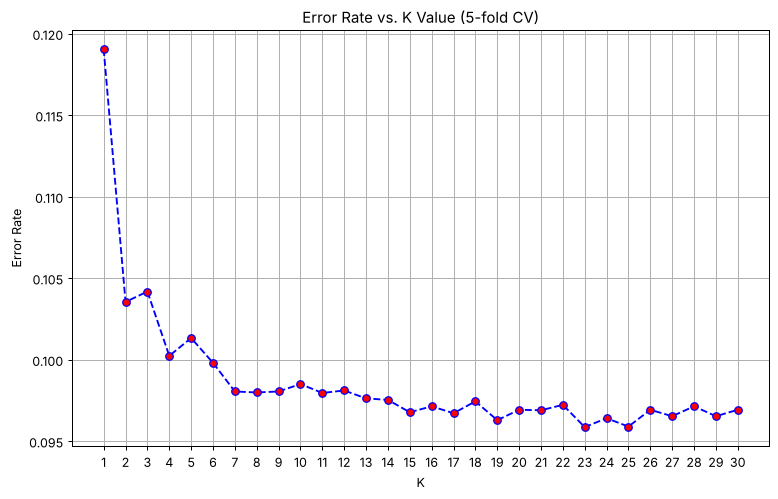

In [ ]:
# (10 pts) Step 7: Plot the error rate for different K values
plt.figure(figsize=(10, 6))
plt.plot(k_values, error_rates, marker="o", linestyle="--", color="blue", markerfacecolor="red")
plt.title("Error Rate vs. K Value (5-fold CV)")
plt.xlabel("K")
plt.ylabel("Error Rate")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [ ]:
# (10 pts) Step 8: Find and print the optimal K (K with the minimum error rate)
optimal_k = list(k_values)[int(np.argmin(error_rates))]
print("Optimal K:", optimal_k)
print("Minimum CV error rate:", round(min(error_rates), 4))

Optimal K: 23
Minimum CV error rate: 0.0959


In [ ]:
# (10 pts) Step 9: Train the final KNN model with the optimal K
final_knn = KNeighborsClassifier(n_neighbors=optimal_k)
final_knn.fit(X_train, y_train)
print(final_knn)

KNeighborsClassifier(n_neighbors=23)


In [ ]:
# (10 pts) Step 10: Make predictions
y_pred = final_knn.predict(X_test)
print("First 20 predictions:", y_pred[:20])
print("First 20 actual     :", y_test.values[:20])

First 20 predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1]
First 20 actual     : [0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 1]


Accuracy: 0.9084
Test error rate: 0.0916

Confusion Matrix:
[[7176  134]
 [ 621  307]]

Classification Report:
              precision    recall  f1-score   support

          no       0.92      0.98      0.95      7310
         yes       0.70      0.33      0.45       928

    accuracy                           0.91      8238
   macro avg       0.81      0.66      0.70      8238
weighted avg       0.90      0.91      0.89      8238



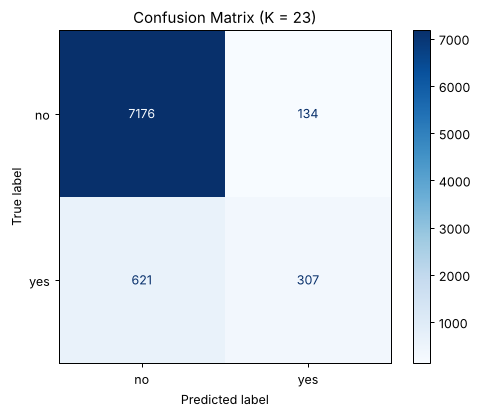

In [ ]:
# (10 pts) Step 11: Model evaluation
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Test error rate:", round(1 - accuracy_score(y_test, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["no", "yes"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["no", "yes"], cmap="Blues")
plt.title(f"Confusion Matrix (K = {optimal_k})")
plt.show()